In [2]:
import pandas as pd
import numpy as np
import lifelines as ll
import sksurv as sks
import matplotlib.pyplot as plt
from bart_survival import surv_bart as sb


import lifelines as ll
from lifelines import KaplanMeierFitter
import subprocess
import threading as th
import multiprocessing as mp
import sys
# sys.path.append("../src/")
import sim_adj as sm
import arviz as az

In [89]:
def get_sim(rng, N, type, x_vars, VAR_CLASS, VAR_PROB, scale_f, shape_f, cens_scale):
    x_mat = sm.get_x_matrix(
        N = N,
        x_vars = x_vars, 
        VAR_CLASS=VAR_CLASS,
        VAR_PROB= VAR_PROB,
        rng = rng
    )

    event_dict, sv_true, sv_scale_true = sm.simulate_survival(
        x_mat = x_mat,
        scale_f=scale_f,
        shape_f=shape_f,
        cens_scale=cens_scale,
        rng = rng
    )
    
    return type, x_mat, event_dict, sv_true, sv_scale_true


def get_quant_times(sv_true_c, sv_true, quant=[0.9,0.75,0.5,0.25,0.1]):
	qnt_t = []
	for i in quant:
		tmp = np.abs(sv_true_c - i)
		idx = tmp == tmp.min()
		qnt_t.append(sv_true["true_times"][idx])
	return np.array(qnt_t)

def get_quant_events(qnt_t, event):
	q = np.array(qnt_t)
	et_ = event["t_event"].copy()
	et_out = event["t_event"].copy()
	es_out = event["status"].copy()
	for i in range(q.shape[0]):
		if i == 0:
			msk = et_<=q[i]
			et_out[msk] = q[i]
			# print(np.unique(et_out))
		else:
			msk = (q[i-1] < et_) & (et_ <= q[i])
			et_out[msk] = q[i]
			# print(np.unique(et_out))
			if i == q.shape[0]-1:
				msk = et_ > q[i]
				et_out[msk] = q[i]
				es_out[msk] = 0

	return {"t_event":et_out, "status":es_out}

def ed_sub(event_dict, x_mat, x_val):
    msk = x_mat[:,0] == x_val
    ed_out = {
        "t_event":event_dict["t_event"][msk],
        "status":event_dict["status"][msk]
    }
    uniq_t = np.unique(ed_out["t_event"])
    return ed_out, uniq_t

def ci_at_times(ci, k_t, uniq_t):
    k_s = k_t.shape[0]
    uniq_idx =np.arange(uniq_t.shape[0])
    out = np.zeros(shape=(2,uniq_t.shape[0]))
    for i in range(k_s):
        if i == k_s-1:
            msk = uniq_idx[uniq_t >= k_t[i]]
        else:
            lwr = k_t[i]
            upr = k_t[i+1]
            msk = uniq_idx[(lwr<=uniq_t) & (uniq_t < upr)]
        out[:,msk] = ci[:,i].reshape(-1,1)
    return out

def twopop_kpm(event_dict, uniq_t):
    kpm = ll.KaplanMeierFitter()
    kpm.fit(durations=event_dict["t_event"], event_observed=event_dict["status"])
    k1_a = kpm.survival_function_at_times(uniq_t).to_numpy()
    k1_ci = kpm.confidence_interval_survival_function_.values[1:,:].T
    k_t = kpm.timeline[1:]
    ci_a = ci_at_times(k1_ci, k_t, uniq_t)
    return k1_a, ci_a, uniq_t

def get_py_bart_surv(x_mat, event_dict, model_dict, sampler_dict):
    trn = sb.get_surv_pre_train(y_time = event_dict["t_event"], y_status=event_dict["status"], x = x_mat, weight=None)
    post_test = sb.get_posterior_test(y_status=event_dict["status"], y_time=event_dict["t_event"], x=x_mat)
    small_post_x = np.unique(post_test["post_x"][:,0]).reshape(-1,1)
    small_coords = np.hstack([np.repeat(0, small_post_x.shape[0]), np.repeat(1, small_post_x.shape[0]), ])
    small_post_x = np.vstack([small_post_x, small_post_x])
    BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)

    BSM.fit(y=trn["y"], X=trn["x"][:,0].reshape(-1,1), weights=trn["w"], coords = trn["coord"], random_seed=99)
    
    post1 = BSM.sample_posterior_predictive(X_pred=small_post_x, coords=small_coords)
    sv_prob = sb.get_sv_prob(post1)
    sv_m = sv_prob["sv"].mean(1).mean(0)
    uniq_t = BSM.uniq_times
    sv_q = np.quantile(sv_prob["sv"].mean(1), [0.025,0.975], axis=0)
    del BSM
    
    childs = mp.active_children()
    for child in childs:
        child.kill()
    return sv_prob, uniq_t

def get_hdi_ci_1(pb_sv):
    s1 = pb_sv["sv"].shape[0]
    s2 = pb_sv["sv"].shape[1]
    s3 = pb_sv["sv"].shape[2]
    hdi_pre = az.convert_to_dataset(pb_sv["sv"].reshape(1,s1,s2,s3))
    #low-high
    hdi_lh = az.hdi(hdi_pre, hdi_prob=.95).x.values
    # low-high
    ci_lh = np.quantile(pb_sv["sv"], [0.025, 0.975], 0)
    return hdi_lh, ci_lh


def check_array(v):
    if type(v) == list:
        v = np.array(v)
    return v

def rmse(true, est):
    true = check_array(true)
    est = check_array(est)
    out = np.sqrt(np.power((true - est),2).mean(0))
    return out

def bias(true, est):
    true = check_array(true)
    est = check_array(est)
    out = (true-est).mean(0)
    return out

def coverage(true, ci_est, calc = True):
    true = check_array(true)
    ci_est = check_array(ci_est)

    l = np.round(ci_est[:,0,:],4)
    u = np.round(ci_est[:,1,:],4)
    true = np.round(true, 4)
    out = []
    for i in range(true.shape[1]):
        z = (l[:,i] <= true[:,i]) & (true[:,i] <= u[:,i])
        out.append(z)
    out = np.array(out).T
    if calc:
        return out.sum(0)/out.shape[0]
    else:
        return out


In [ ]:
rng = np.random.default_rng(13)
n = 400
simple_1_1 = {
    "type": "Simple, 1 group, 20% cens",
    "x_vars": 1, 
    "VAR_CLASS": [2],
    "VAR_PROB":[1],
    "scale_f": "7*x_mat[:,0]",
    "shape_f": "3",
    # "cens_scale":7
	"cens_scale":1.3
}

# Cond 1
SPLIT_RULES1 =  [
	"pmb.ContinuousSplitRule()", 
]
MODEL_DICT1 = {"trees": 100,
	"split_rules": SPLIT_RULES1
}
SAMPLER_DICT1 = {
	"draws": 1000,
	"tune": 100,
	"cores": 12,
	"chains": 12,
	"compute_convergence_checks": False,
	# "pgbart":{
    #             "num_particles":2,
    #             "batch":(.1,.1)
    #         }
}

model_dict = MODEL_DICT1
sampler_dict = SAMPLER_DICT1


scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, n, **simple_1_1)
print(event_dict["status"].mean())

sv_true_mean = sv_true["sv_true"].mean(0)
qnt_t = get_quant_times(sv_true_c=sv_true_mean, sv_true= sv_true).flatten()
print(qnt_t)
event_dict = get_quant_events(qnt_t=qnt_t, event=event_dict)

x_tst, x_tst_idx = np.unique(x_mat, return_index=True)
cens_perc = event_dict["status"][event_dict["status"] == 0].shape[0]/event_dict["status"].shape[0]
    
# get uniq times and quantiles as indexes
uniq_t = np.unique(event_dict["t_event"]) 
print(uniq_t)
    
sv_true_r0 = sv_true["sv_true"][int(x_tst_idx[0]),:]
sv_true_r0 = sv_true_r0[qnt_t.astype("int") - 1]
# # sv_true_r1 = sv_true["sv_true"][int(x_tst_idx[1]),:]
# sv_true_r1 = sv_true_r1[qnt_t.astype("int") - 1]
# x_tst_idx

ed0, uniq_t2 = ed_sub(event_dict, x_mat, 1)
k_sv = twopop_kpm(ed0, uniq_t)

k_sv
pb_sv,  uniq_t = get_py_bart_surv(x_mat, event_dict, model_dict, sampler_dict)
pb_sv_m = pb_sv["sv"].mean(1).mean(0)
hdi, ci = get_hdi_ci_1(pb_sv)
    

NameError: name 'np' is not defined

In [93]:
sv_true_r0

array([0.92430128, 0.69459142, 0.53273157, 0.22476241, 0.11938945])

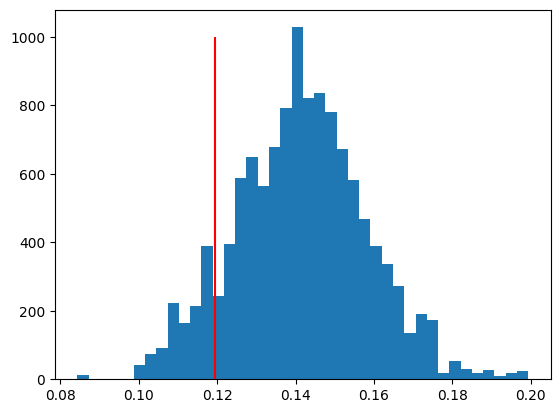

In [85]:
plt.hist(pb_sv["sv"].mean(1)[:,4], bins=40)
plt.vlines(sv_true_r0[4], 0, 1000, color="red")

In [ ]:
ci,hdi

(array([[[0.94836791, 0.70472739, 0.51044368, 0.18055314, 0.10867012],
         [0.94836791, 0.70472739, 0.51044368, 0.18055314, 0.10867012]],
 
        [[0.97282999, 0.76900038, 0.59132303, 0.25297718, 0.17431684],
         [0.97282999, 0.76900038, 0.59132303, 0.25297718, 0.17431684]]]),
 array([[[0.9489902 , 0.97320708],
         [0.70471995, 0.76828068],
         [0.51509887, 0.59522245],
         [0.18110587, 0.2531178 ],
         [0.10867012, 0.17396082]],
 
        [[0.9489902 , 0.97320708],
         [0.70471995, 0.76828068],
         [0.51509887, 0.59522245],
         [0.18110587, 0.2531178 ],
         [0.10867012, 0.17396082]]]))

In [87]:
k_sv

(array([0.9625    , 0.73803004, 0.55668551, 0.21115657, 0.14267336]),
 array([[0.93856689, 0.68464053, 0.49445771, 0.15975111, 0.09838919],
        [0.97722187, 0.78382996, 0.61436436, 0.26750757, 0.19492714]]),
 array([3., 5., 6., 8., 9.]))

In [ ]:
def sim_2s(seed, n, scenario, SPLIT_RULES, model_dict, sampler_dict):
    # set rng as seed given
    if type(seed) is int:
        rng = np.random.default_rng(seed)
    else:
        rng = seed
    # generate survival simulation
    scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, n, **scenario)
    
    #get mean survival
    sv_true_mean = sv_true["sv_true"].mean(0)
    qnt_t = get_quant_times(sv_true_c=sv_true_mean, sv_true= sv_true).flatten()
    print(qnt_t)
    event_dict = get_quant_events(qnt_t=qnt_t, event=event_dict)

    
    # get the unique x_test
    x_tst, x_tst_idx = np.unique(x_mat, return_index=True)
    cens_perc = event_dict["status"][event_dict["status"] == 0].shape[0]/event_dict["status"].shape[0]
    
    # get uniq times and quantiles as indexes
    uniq_t = np.unique(event_dict["t_event"]) 
    print(uniq_t)
    
    # qnt_t, qnt_idx = get_quant_times(uniq_t, uniq = False)
    true_t = sv_true["true_times"]
    
    # singular sv true
    sv_true_r0 = sv_true["sv_true"][int(x_tst_idx[0]),:]
    sv_true_r0 = sv_true_r0[qnt_t.astype("int") - 1]
    sv_true_r1 = sv_true["sv_true"][int(x_tst_idx[1]),:]
    sv_true_r1 = sv_true_r1[qnt_t.astype("int") - 1]
    
    # fit kpm    
    ed1, uniq_t1 = ed_sub(event_dict, x_mat, 0)
    ed2, uniq_t2 = ed_sub(event_dict, x_mat, 1)
    k_sv1 = twopop_kpm(ed1, uniq_t)
    k_sv2 = twopop_kpm(ed2, uniq_t)
    
    # print(x_mat)
    # fit bart_py
    pb_sv = get_py_bart_surv2(x_mat=x_mat, event_dict=event_dict, model_dict=model_dict, sampler_dict=sampler_dict)

    # fit bart_r
    r_sv = get_r_bart2(event_dict, x_mat)

    return {"cens_perc":cens_perc, 
        "uniq_t":uniq_t, 
        "sv_true_u":(sv_true_r0, sv_true_r1),
        "pb_sv":pb_sv, 
        # "pb_hdi":hdi[0].T, 
        # "pb_ci":ci[:,0,:], 
        "r_sv":r_sv, 
        "k_sv":(k_sv1, k_sv2)
        }

    # return (cens_perc, true_t, uniq_t, (qnt_t, qnt_t-1)),(sv_true_r0, sv_true_r1),(k_sv1, k_sv2), pb_sv, r_sv


In [ ]:
simple_1_1 = {
    "type": "Simple, 1 group, 20% cens",
    "x_vars": 1, 
    "VAR_CLASS": [2],
    "VAR_PROB":[1],
    "scale_f": "7*x_mat[:,0]",
    "shape_f": "3",
    "cens_scale":7
	# "cens_scale":1.3
}

# Cond 1
SPLIT_RULES1 =  [
	"pmb.ContinuousSplitRule()", 
]
MODEL_DICT1 = {"trees": 100,
	"split_rules": SPLIT_RULES1
}
SAMPLER_DICT1 = {
	"draws": 300,
	"tune": 50,
	"cores": 12,
	"chains": 12,
	"compute_convergence_checks": False,
	"pgbart":{
                "num_particles":5,
                "batch":(.1,.1)
            }
}
